# Quy luật hành vi duyệt web cho log tổng hợp

**Mục tiêu:** đo những quy luật mà bộ sinh log cần để dựng lưu lượng duyệt web quanh các đơn hàng OLTP. Dashboard log chỉ **đếm request** (lượt xem, thêm giỏ, thanh toán, request theo giờ/route), nên notebook chỉ đo những gì làm thay đổi các con số đó:

| Mã | Câu hỏi | Cách có số |
|---|---|---|
| L1 | Cứ 1 phiên có mua thì có bao nhiêu phiên chỉ xem? | Đo |
| L2 | Mỗi phiên xem bao nhiêu sản phẩm? | Đo |
| L3 | Hai lần bấm cách nhau bao lâu? | Đo |
| — | Giỏ hàng bị bỏ, sản phẩm nào được xem, request phụ, khách ẩn danh… | Giả định (mục 4) |

Mỗi quy luật đo gồm ba phần, giống notebook OLTP:
1. **Dữ liệu cho thấy gì:** biểu đồ hoặc bảng số đo thật.
2. **Quy luật:** một câu, ít tham số nhất có thể.
3. **Kiểm tra:** so mô hình với thực tế, sai lệch tính bằng điểm phần trăm.

Nguồn: **eCommerce Behavior**, sự kiện `view`, `cart`, `purchase` từ 2/10 đến 31/10/2019 của một cửa hàng đa ngành ở Nga. Mỗi quy luật được đo trên **toàn bộ dữ liệu và trên nhóm `apparel`**. Dạng quy luật lặp lại ở hai nhóm thì coi là chuyển được; tham số đưa vào YAML lấy theo `apparel`, nhóm gần với shop thời trang nhất. Kết quả nằm trong `generator/configs/access_logs.yml`.

In [1]:
%matplotlib inline
import datetime as dt
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import yaml
from scipy import optimize, stats

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent.parent
data_dir = repo_root / "data" / "generator" / "eda" / "raw"
plt.rcParams["figure.figsize"] = (10, 3.6)
pl.Config.set_tbl_rows(40)


def percent(values):
    return np.round(np.asarray(values) * 100, 1)

## 0. Dữ liệu và cohort

Một phiên là một `user_session` (được băm thành số để tiết kiệm bộ nhớ). Các sự kiện ngày 1/11 trong file tháng 11 chỉ được đọc để nhận ra những phiên vắt qua nửa đêm 31/10. Mọi phiên có sự kiện ngày 1/10 hoặc 1/11 (giờ UTC) đều bị loại: phiên ngày 1/10 có thể đã bắt đầu từ tháng 9, phiên chạm 1/11 bị cắt ở cuối tháng. Cohort còn 30 ngày, từ 2/10 đến 31/10.

Nhóm `apparel`: phiên mà mọi sự kiện có `category_code` đều thuộc nhóm `apparel` (và có ít nhất một sự kiện như vậy).

In [2]:
SCHEMA = {"user_session": pl.Utf8, "category_code": pl.Utf8}


def scan(month):
    return pl.scan_csv(data_dir / "ecommerce_behavior" / f"2019-{month}.csv", schema_overrides=SCHEMA).select(
        "event_time", "event_type", "user_session", "category_code"
    )


raw = (
    pl.concat([scan("Oct"), scan("Nov").filter(pl.col("event_time").str.starts_with("2019-11-01"))])
    .with_columns(ts=pl.col("event_time").str.replace(" UTC", "").str.to_datetime(time_zone="UTC"))
    .collect(engine="streaming")
)
raw.select("ts", "event_type", "user_session", "category_code").null_count()

ts,event_type,user_session,category_code
u32,u32,u32,u32
0,0,2,13976404


In [3]:
raw = raw.filter(pl.col("user_session").is_not_null())
all_events = raw.select(
    "ts",
    day=pl.col("ts").dt.date(),
    event_type=pl.col("event_type").cast(pl.Categorical),
    session=pl.col("user_session").hash(),
    has_category=pl.col("category_code").is_not_null(),
    is_apparel=pl.col("category_code").str.starts_with("apparel").fill_null(False),
)
del raw
boundary = all_events.filter(pl.col("day").is_in([dt.date(2019, 10, 1), dt.date(2019, 11, 1)])).select("session").unique()
events = all_events.join(boundary, on="session", how="anti").sort("session", "ts")
del all_events
sessions = events.group_by("session").agg(
    start=pl.col("ts").min(),
    views=(pl.col("event_type") == "view").sum(),
    purchases=(pl.col("event_type") == "purchase").sum(),
    apparel=pl.col("has_category").any() & (pl.col("is_apparel") | ~pl.col("has_category")).all(),
).with_columns(buying=pl.col("purchases") > 0)
print(f"{boundary.height:,} phiên chạm biên bị loại; còn {sessions.height:,} phiên, {events.height:,} sự kiện")
print(f"phiên có mua: {sessions['buying'].sum():,}; phiên apparel: {sessions['apparel'].sum():,}, "
      f"trong đó có mua: {sessions.filter(pl.col('apparel'))['buying'].sum():,}")
events.select("ts").describe()

589,629 phiên chạm biên bị loại; còn 8,974,352 phiên, 41,191,294 sự kiện
phiên có mua: 613,292; phiên apparel: 303,167, trong đó có mua: 7,152


statistic,ts
str,str
"""count""","""41191294"""
"""null_count""","""0"""
"""mean""","""2019-10-16 23:58:40.487529+00:…"
"""std""",null
"""min""","""2019-10-02 00:00:08+00:00"""
"""25%""","""2019-10-10 00:13:29+00:00"""
"""50%""","""2019-10-16 18:38:25+00:00"""
"""75%""","""2019-10-24 04:09:44+00:00"""
"""max""","""2019-10-31 23:59:59+00:00"""


**Nhận xét:** sau khi loại 589.629 phiên chạm biên, cohort còn **8.974.352 phiên** và 41,2 triệu sự kiện trong 30 ngày (2/10–31/10), trong đó 613.292 phiên có mua. Nhóm `apparel` có 303.167 phiên, trong đó 7.152 phiên có mua: đủ để so sánh với toàn bộ dữ liệu.

In [4]:
assert events.filter(pl.col("day").is_in([dt.date(2019, 10, 1), dt.date(2019, 11, 1)])).height == 0
assert events.filter(pl.col("day") == dt.date(2019, 10, 31)).height > 0
assert sessions["session"].n_unique() == sessions.height
assert sessions.filter(pl.col("buying")).height > 500_000
assert 250_000 < sessions.filter(pl.col("apparel")).height < 450_000

## 1. L1 — Mỗi phiên mua đi kèm bao nhiêu phiên không mua?

Generator dựng lưu lượng quanh số đơn OLTP, nên cần biết tỷ lệ r = phiên không mua ÷ phiên có mua. Nếu r ổn định giữa các ngày thì chỉ cần một con số.

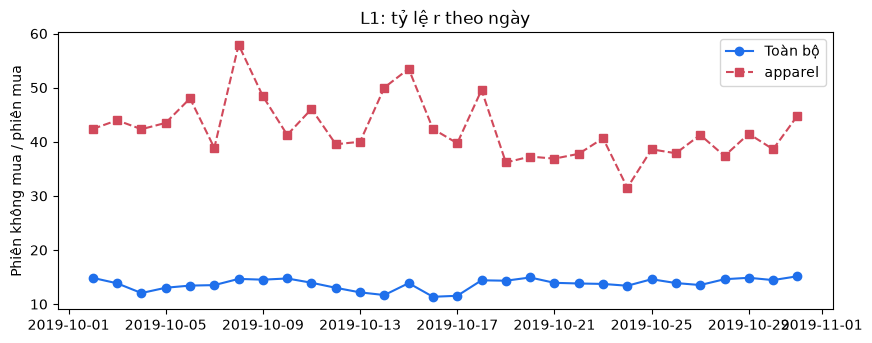

nhóm,r cả kỳ,r trung vị theo ngày,r p10 theo ngày,r p90 theo ngày
str,f64,f64,f64,f64
"""Toàn bộ""",13.63,13.89,12.05,14.85
"""apparel""",41.39,41.27,37.27,49.58


In [5]:
daily_ratio = (
    sessions.with_columns(day=pl.col("start").dt.date())
    .group_by("day", "apparel")
    .agg(buying=pl.col("buying").sum(), non_buying=(~pl.col("buying")).sum())
    .with_columns(ratio=pl.col("non_buying") / pl.col("buying"))
    .sort("day")
)
non_buying_per_buying = (~sessions["buying"]).sum() / sessions["buying"].sum()
apparel_sessions = sessions.filter(pl.col("apparel"))
non_buying_per_buying_apparel = (~apparel_sessions["buying"]).sum() / apparel_sessions["buying"].sum()
all_daily = (
    sessions.with_columns(day=pl.col("start").dt.date())
    .group_by("day").agg(ratio=(~pl.col("buying")).sum() / pl.col("buying").sum()).sort("day")
)
apparel_daily = daily_ratio.filter(pl.col("apparel"))
fig, ax = plt.subplots()
ax.plot(all_daily["day"], all_daily["ratio"], "o-", color="#1f6feb", label="Toàn bộ")
ax.plot(apparel_daily["day"], apparel_daily["ratio"], "s--", color="#d1495b", label="apparel")
ax.set(ylabel="Phiên không mua / phiên mua", title="L1: tỷ lệ r theo ngày")
ax.legend()
plt.show()
pl.DataFrame({
    "nhóm": ["Toàn bộ", "apparel"],
    "r cả kỳ": [round(non_buying_per_buying, 2), round(non_buying_per_buying_apparel, 2)],
    "r trung vị theo ngày": [round(all_daily["ratio"].median(), 2), round(apparel_daily["ratio"].median(), 2)],
    "r p10 theo ngày": [round(all_daily["ratio"].quantile(0.1), 2), round(apparel_daily["ratio"].quantile(0.1), 2)],
    "r p90 theo ngày": [round(all_daily["ratio"].quantile(0.9), 2), round(apparel_daily["ratio"].quantile(0.9), 2)],
})

In [6]:
# Độ nhạy: r phụ thuộc cách định nghĩa "phiên apparel". Định nghĩa chặt (mọi sự kiện có danh mục đều là apparel)
# loại phiên dài nhiều hơn, mà phiên có mua thường dài hơn.
session_flags = events.group_by("session").agg(
    any_apparel=pl.col("is_apparel").any(),
    bought_apparel=((pl.col("event_type") == "purchase") & pl.col("is_apparel")).any(),
)
flagged = sessions.join(session_flags, on="session")
definitions = {
    "Chặt: mọi sự kiện có danh mục là apparel; mua = có mua (đang dùng)": (pl.col("apparel"), pl.col("buying")),
    "Rộng: có xem apparel; mua = có mua bất kỳ": (pl.col("any_apparel"), pl.col("buying")),
    "Rộng: có xem apparel; mua = mua sản phẩm apparel": (pl.col("any_apparel"), pl.col("bought_apparel")),
}
rows = []
for name, (in_group, is_buying) in definitions.items():
    frame = flagged.filter(in_group).with_columns(is_buying=is_buying)
    buying = frame.filter(pl.col("is_buying"))
    rows.append({"định nghĩa": name, "phiên": frame.height, "phiên có mua": buying.height,
                 "r": round((~frame["is_buying"]).sum() / buying.height, 2),
                 "lượt xem TB phiên mua": round(buying.filter(pl.col("views") > 0)["views"].mean(), 2)})
r_sensitivity = pl.DataFrame(rows)
with pl.Config(fmt_str_lengths=80, tbl_width_chars=200):
    display(r_sensitivity)

định nghĩa,phiên,phiên có mua,r,lượt xem TB phiên mua
str,i64,i64,f64,f64
"""Chặt: mọi sự kiện có danh mục là apparel; mua = có mua (đang dùng)""",303167,7152,41.39,9.58
"""Rộng: có xem apparel; mua = có mua bất kỳ""",372094,11525,31.29,12.25
"""Rộng: có xem apparel; mua = mua sản phẩm apparel""",372094,7081,51.55,9.93


**Nhận xét:** với toàn bộ dữ liệu, mỗi phiên có mua đi kèm khoảng **13,6 phiên không mua**, và tỷ lệ này ổn định giữa các ngày (80% số ngày nằm trong khoảng 12,0–14,9). Nhóm `apparel` cũng ổn định theo ngày nhưng ở mức cao hơn gấp ba: **41,4** (37,3–49,6). Khách xem quần áo ở cửa hàng này mua ít hơn hẳn, có lẽ vì quần áo là ngành phụ của một cửa hàng chủ yếu bán đồ điện tử.

**Độ nhạy theo định nghĩa:** giá trị r của `apparel` phụ thuộc mạnh vào cách xác định "phiên apparel". Định nghĩa đang dùng (chặt) cho r = 41,4; định nghĩa rộng cho **31,3** (có mua bất kỳ) đến **51,6** (chỉ tính mua sản phẩm apparel).

**Quy luật L1:** số phiên không mua = r × số phiên có mua, r không đổi theo ngày. Giá trị lấy theo `apparel` (r = 41,4), nhưng **khoảng hợp lý là 31–52**. Vì r quyết định tổng lưu lượng log, đây là tham số nên chỉnh đầu tiên nếu log quá nhiều hoặc quá ít.

## 2. L2 — Một phiên có bao nhiêu lượt xem sản phẩm?

Đo số lượt `view` mỗi phiên, tách phiên có mua và không mua. Thử hai phân phối một tham số, chọn cái lệch ít hơn:
- **Hình học:** sau mỗi lượt xem, khách xem tiếp với xác suất 1 − p (p = 1/trung bình).
- **Log-series:** cùng dạng đuôi dài đã dùng cho số đơn mỗi khách ở notebook OLTP.

Phiên không có lượt xem nào (chỉ có sự kiện giỏ hoặc mua) được báo riêng và không đưa vào fit.

kind,group,sessions,zero_view_%,mean_views,model,param,max_error_pp,other_model_error_pp
str,str,i64,f64,f64,str,f64,f64,f64
"""buying""","""Toàn bộ""",613292,0.1,5.57,"""geometric""",0.1796,8.3,16.3
"""buying""","""apparel""",7152,0.1,9.58,"""geometric""",0.1044,6.4,19.4
"""non_buying""","""Toàn bộ""",8361060,0.0,4.32,"""zero_truncated_log_series""",0.9138,1.2,15.4
"""non_buying""","""apparel""",296015,0.0,4.71,"""zero_truncated_log_series""",0.9239,1.3,13.3


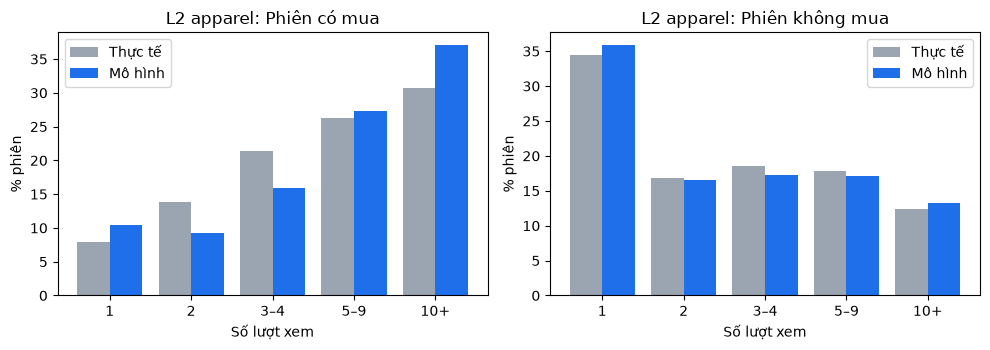

kind,group,nguồn,1,2,3–4,5–9,10+
str,str,str,f64,f64,f64,f64,f64
"""buying""","""Toàn bộ""","""thực tế""",17.1,23.0,24.5,21.1,14.2
"""buying""","""Toàn bộ""","""mô hình""",18.0,14.7,22.0,28.5,16.8
"""buying""","""apparel""","""thực tế""",7.9,13.8,21.4,26.3,30.7
"""buying""","""apparel""","""mô hình""",10.4,9.3,15.9,27.3,37.1
"""non_buying""","""Toàn bộ""","""thực tế""",38.5,17.4,17.6,15.8,10.7
"""non_buying""","""Toàn bộ""","""mô hình""",37.3,17.0,17.5,16.8,11.4
"""non_buying""","""apparel""","""thực tế""",34.5,16.8,18.5,17.8,12.4
"""non_buying""","""apparel""","""mô hình""",35.9,16.6,17.3,17.1,13.2


In [7]:
BUCKETS = ["1", "2", "3–4", "5–9", "10+"]


def bucket_share(values, edges=(1, 2, 3, 5, 10)):
    values = np.asarray(values)
    bounds = list(edges) + [np.inf]
    return np.array([((values >= lo) & (values < hi)).mean() for lo, hi in zip(bounds[:-1], bounds[1:])])


def model_buckets(model, param, edges=(1, 2, 3, 5, 10)):
    k = np.arange(1, edges[-1])
    if model == "geometric":
        pmf = param * (1 - param) ** (k - 1)
    else:
        pmf = -(param**k) / (k * np.log1p(-param))
    bounds = list(edges)
    shares = [pmf[(k >= lo) & (k < hi)].sum() for lo, hi in zip(bounds[:-1], bounds[1:])]
    return np.array(shares + [1 - pmf.sum()])


def log_series_theta(mean):
    return optimize.brentq(lambda t: -t / ((1 - t) * np.log1p(-t)) - mean, 1e-9, 1 - 1e-12)


def fit_views(values):
    shares = bucket_share(values)
    fits = {"geometric": 1 / values.mean(), "zero_truncated_log_series": log_series_theta(values.mean())}
    errors = {m: np.abs(model_buckets(m, p) - shares).max() * 100 for m, p in fits.items()}
    return shares, fits, errors


# Dạng mô hình chọn trên nhóm toàn bộ (nhiều dữ liệu); tham số đưa vào YAML lấy từ apparel.
rows, shares_rows, views_models = [], [], {}
for kind, condition in (("buying", pl.col("buying")), ("non_buying", ~pl.col("buying"))):
    chosen = None
    for group, frame in (("Toàn bộ", sessions), ("apparel", apparel_sessions)):
        subset = frame.filter(condition)
        values = subset.filter(pl.col("views") > 0)["views"].to_numpy()
        shares, fits, errors = fit_views(values)
        chosen = chosen or min(errors, key=errors.get)
        if group == "apparel":
            views_models[kind] = {"model": chosen, ("p" if chosen == "geometric" else "theta"): round(float(fits[chosen]), 4)}
        rows.append({"kind": kind, "group": group, "sessions": subset.height,
                     "zero_view_%": percent((subset["views"] == 0).mean()), "mean_views": round(values.mean(), 2),
                     "model": chosen, "param": round(float(fits[chosen]), 4), "max_error_pp": round(errors[chosen], 1),
                     "other_model_error_pp": round(min(v for m, v in errors.items() if m != chosen), 1)})
        for source, values_pct in (("thực tế", percent(shares)), ("mô hình", percent(model_buckets(chosen, fits[chosen])))):
            shares_rows.append({"kind": kind, "group": group, "nguồn": source, **dict(zip(BUCKETS, values_pct.tolist()))})
l2_check = pl.DataFrame(rows)
display(l2_check)
l2_shares = pl.DataFrame(shares_rows)
fig, axes = plt.subplots(1, 2)
for ax, kind, title in zip(axes, ("buying", "non_buying"), ("Phiên có mua", "Phiên không mua")):
    frame = l2_shares.filter((pl.col("kind") == kind) & (pl.col("group") == "apparel"))
    x = np.arange(len(BUCKETS))
    ax.bar(x - 0.2, frame.filter(pl.col("nguồn") == "thực tế").select(BUCKETS).row(0), 0.4, color="#9aa5b1", label="Thực tế")
    ax.bar(x + 0.2, frame.filter(pl.col("nguồn") == "mô hình").select(BUCKETS).row(0), 0.4, color="#1f6feb", label="Mô hình")
    ax.set(xticks=x, xticklabels=BUCKETS, xlabel="Số lượt xem", ylabel="% phiên", title=f"L2 apparel: {title}")
    ax.legend()
plt.tight_layout()
plt.show()
l2_shares

**Nhận xét:**
- **Phiên không mua:** log-series khớp tốt ở cả hai nhóm (lệch khoảng 1,2–1,3 điểm %), tham số gần như trùng nhau (θ ≈ 0,91 và 0,92). Khoảng 35–39% phiên chỉ xem đúng một sản phẩm rồi rời đi; trung bình khoảng 5 lượt xem.
- **Phiên có mua:** khách xem nhiều hơn (trung bình 5,6 lượt; với `apparel` là 9,6). Số lượt xem có **đỉnh ở 2 lượt**, nên phân phối hình học, vốn luôn giảm dần, lệch tối đa 6–8 điểm %. Mức lệch này được chấp nhận vì log-series còn lệch nhiều hơn (16–19 điểm %).
- Gần như mọi phiên đều có ít nhất một lượt xem (phiên 0 lượt xem chiếm ≤ 0,1%).

**Quy luật L2:** số lượt xem của phiên không mua theo **log-series (θ = 0,924)**, của phiên có mua theo **phân phối hình học (p = 0,104)**; tham số lấy từ `apparel`.

In [8]:
assert 5 < non_buying_per_buying < 30
for kind in ("buying", "non_buying"):
    assert views_models[kind]["model"] in {"geometric", "zero_truncated_log_series"}
assert l2_check["max_error_pp"].max() < 10
assert r_sensitivity.height == 3
assert r_sensitivity["r"].min() <= non_buying_per_buying_apparel <= r_sensitivity["r"].max()
assert 25 < non_buying_per_buying_apparel < 60

## 3. L3 — Hai sự kiện liên tiếp trong phiên cách nhau bao lâu?

Đo số giây giữa hai sự kiện liên tiếp của cùng một phiên. Khoảng cách bằng 0 (hai sự kiện trong cùng một giây) được báo riêng; phân phối log-normal được fit trên các khoảng cách lớn hơn 0.

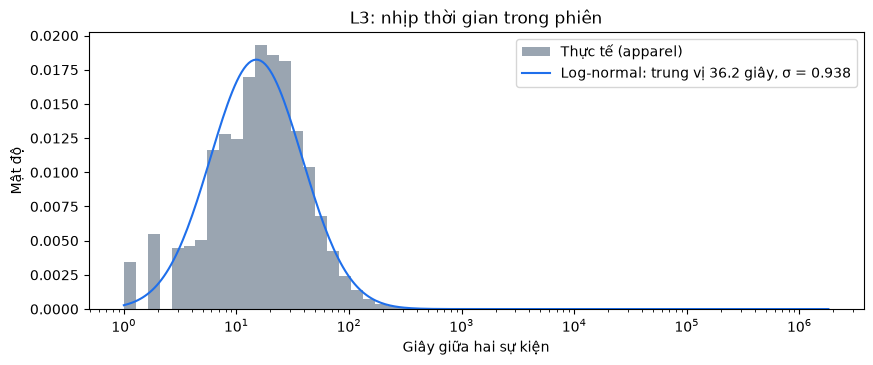

group,gaps,zero_%,median_seconds,sigma,max_error_pp
str,i64,f64,f64,f64,f64
"""Toàn bộ""",32216942,0.1,37.0,1.114,6.5
"""apparel""",1169592,0.0,36.2,0.938,4.4


group,nguồn,≤ 10 giây,10–60 giây,1–5 phút,> 5 phút
str,str,f64,f64,f64,f64
"""Toàn bộ""","""thực tế""",10.0,61.2,25.3,3.4
"""Toàn bộ""","""mô hình""",12.0,54.7,30.2,3.0
"""apparel""","""thực tế""",7.5,66.4,24.3,1.9
"""apparel""","""mô hình""",8.5,62.0,28.3,1.2


In [9]:
apparel_ids = sessions.filter(pl.col("apparel")).select("session")
gaps = events.select(
    "session", gap=(pl.col("ts").diff().over("session").dt.total_seconds())
).filter(pl.col("gap").is_not_null())
GAP_BUCKETS = ["≤ 10 giây", "10–60 giây", "1–5 phút", "> 5 phút"]
GAP_EDGES = [0, 10, 60, 300, np.inf]
rows, shares_rows, gap_fits = [], [], {}
for group, frame in (("Toàn bộ", gaps), ("apparel", gaps.join(apparel_ids, on="session"))):
    values = frame["gap"].to_numpy()
    positive = values[values > 0]
    log_values = np.log(positive)
    median, sigma = float(np.exp(log_values.mean())), float(log_values.std())
    gap_fits[group] = {"median_seconds": round(median, 1), "sigma": round(sigma, 3), "zero_share": round(float((values == 0).mean()), 4)}
    observed = np.array([((positive > lo) & (positive <= hi)).mean() for lo, hi in zip(GAP_EDGES[:-1], GAP_EDGES[1:])])
    cdf = stats.lognorm.cdf(GAP_EDGES[1:-1], sigma, scale=median)
    model = np.diff(np.concatenate([[0], cdf, [1]]))
    rows.append({"group": group, "gaps": len(values), "zero_%": percent((values == 0).mean()),
                 "median_seconds": round(median, 1), "sigma": round(sigma, 3),
                 "max_error_pp": round(float(np.abs(observed - model).max() * 100), 1)})
    for source, shares in (("thực tế", observed), ("mô hình", model)):
        shares_rows.append({"group": group, "nguồn": source, **dict(zip(GAP_BUCKETS, percent(shares).tolist()))})
event_gap = gap_fits["apparel"]
l3_check = pl.DataFrame(rows)
apparel_gaps = gaps.join(apparel_ids, on="session").filter(pl.col("gap") > 0)["gap"].to_numpy()
bins = np.logspace(0, np.log10(apparel_gaps.max()), 60)
grid = np.logspace(0, np.log10(apparel_gaps.max()), 300)
fig, ax = plt.subplots()
ax.hist(apparel_gaps, bins=bins, density=True, color="#9aa5b1", label="Thực tế (apparel)")
ax.plot(grid, stats.lognorm.pdf(grid, event_gap["sigma"], scale=event_gap["median_seconds"]), color="#1f6feb",
        label=f"Log-normal: trung vị {event_gap['median_seconds']} giây, σ = {event_gap['sigma']}")
ax.set(xscale="log", xlabel="Giây giữa hai sự kiện", ylabel="Mật độ", title="L3: nhịp thời gian trong phiên")
ax.legend()
plt.show()
display(l3_check)
pl.DataFrame(shares_rows)

**Nhận xét:** khoảng cách giữa hai sự kiện có trung vị khoảng **36–37 giây** ở cả hai nhóm; phần lớn (61–66%) rơi vào 10–60 giây và chỉ 2–3% dài hơn 5 phút. Sự kiện trùng giây gần như không có (≤ 0,1%). Log-normal lệch tối đa 4,4 điểm % với `apparel` và 6,5 điểm % với toàn bộ dữ liệu.

**Quy luật L3:** khoảng cách giữa hai request liên tiếp trong phiên theo **log-normal, trung vị 36,2 giây, σ = 0,94** (theo `apparel`). Một nửa số khoảng cách nằm trong 19–68 giây.

In [10]:
assert event_gap["median_seconds"] > 0 and event_gap["sigma"] > 0
assert 0 <= event_gap["zero_share"] < 1
assert l3_check["max_error_pp"].max() < 10

## 4. Giả định: những gì không đo (hoặc không đáng đo)

Các tham số dưới đây được đặt bằng giả định (`source: assumption` trong YAML). Hai dòng đầu từng được đo ở bản notebook trước, nhưng đã bỏ phần đo vì kết quả không ổn định hoặc không đổi được con số nào trên dashboard:
- **Giỏ hàng:** hệ thống thu thập của nguồn ghi thiếu sự kiện `cart` (chỉ 32–53% lượt mua có sự kiện giỏ đi kèm, nhảy theo ngày), và phép hiệu chỉnh không cho cùng kết quả giữa các khối ngày. Hai con số dưới được làm tròn từ phép đo gộp cũ.
- **Sản phẩm được xem:** phép đo cũ cho lượt xem ∝ lượt mua^1,03, tức gần như tỷ lệ thuận; giả định số mũ bằng 1 không đổi kết quả đáng kể và bỏ được một tham số.

| Giả định | Giá trị | Lý do |
|---|---|---|
| Phiên không mua có thêm giỏ rồi bỏ đi (mỗi phiên như vậy thêm 1 sản phẩm) | 7,5% | Làm tròn từ phép đo cũ (7,4%) |
| Sản phẩm thêm giỏ nhưng không mua, trung bình mỗi phiên có mua | 0,09 | Làm tròn từ phép đo cũ (0,086) |
| Lượt xem của một sản phẩm tỷ lệ thuận với lượt mua của nó trong OLTP | có | Số mũ đo được ≈ 1,03 |
| Trong phiên có mua, phần lượt xem rơi vào chính sản phẩm được mua | 32% | Làm tròn từ phép đo cũ (31,8%) |
| Phiên mở đầu bằng `category_list` hoặc `catalog_search` trước lượt xem đầu tiên | luôn có | Khách cần một trang danh sách để chọn sản phẩm; dữ liệu không ghi trang danh sách |
| `cart_read` rồi `checkout_quote` trước `checkout_submit` | luôn có | Đúng thứ tự nghiệp vụ của API checkout |
| Tỷ lệ phiên không mua ở trạng thái ẩn danh | 60% | Dữ liệu không phân biệt đăng nhập; phiên có mua luôn đăng nhập |
| Lưu lượng ngày sale tăng cùng hệ số với số đơn OLTP | có | eCommerce Behavior không có hiệu ứng Black Friday để đo |
| Giờ bắt đầu phiên theo phân bố giờ đặt hàng của OLTP | có | Giữ một nguồn duy nhất cho giờ |

**Đã bỏ hẳn:** hành trình nhiều phiên (khách xem trước vài ngày rồi mới quay lại mua). Log không có mã phiên và không dashboard nào theo dõi khách quay lại, nên quy luật này không đổi được con số nào.

In [11]:
assumed = {
    "funnel": {"non_buying_cart_rate": 0.075, "abandoned_items_per_buying_session": 0.09},
    "products": {"purchased_product_view_share": 0.32},
    "assumptions": {
        "anonymous_non_buying_share": 0.6,
        "request_steps": {
            "category_list_or_search_before_first_view": 1.0,
            "cart_read_before_checkout": 1.0,
            "checkout_quote_before_submit": 1.0,
        },
    },
}

## 5. Tổng hợp

| Mã | Hành vi | Quy luật | Tham số (`apparel`) | Kiểm tra | Giống nhau giữa hai nhóm? |
|---|---|---|---|---|---|
| L1 | Lưu lượng | Phiên không mua = r × phiên có mua | r = 41,4 (khoảng 31–52 tùy định nghĩa `apparel`) | r ổn định theo ngày | Dạng giống; giá trị khác (13,6 với toàn bộ) |
| L2 | Số lượt xem mỗi phiên | Không mua: log-series; có mua: hình học | θ = 0,924; p = 0,104 | Lệch 1,3 và 6,4 điểm % | Không mua: giống; có mua: khác |
| L3 | Nhịp thời gian | Log-normal | trung vị 36,2 giây, σ = 0,94 | Lệch 4,4 điểm % | Giống (trung vị 36–37 giây) |

Mọi tham số đo được mang nhãn **transfer**: chúng đến từ một cửa hàng đa ngành ở Nga, nhóm `apparel` chỉ là ngành phụ của cửa hàng đó. Ô dưới in tham số theo đúng khóa của `generator/configs/access_logs.yml`; ô cuối khẳng định file YAML khớp với các số đo và giả định ở trên.

In [12]:
parameters = {
    "sessions": {
        "non_buying_per_buying": {"value": round(float(non_buying_per_buying_apparel), 2)},
        "views_per_session": {"buying": views_models["buying"], "non_buying": views_models["non_buying"]},
    },
    "timing": {"event_gap_seconds": {"median": event_gap["median_seconds"], "sigma": event_gap["sigma"]}},
}
print(json.dumps(parameters | assumed, ensure_ascii=False, indent=1))

{
 "sessions": {
  "non_buying_per_buying": {
   "value": 41.39
  },
  "views_per_session": {
   "buying": {
    "model": "geometric",
    "p": 0.1044
   },
   "non_buying": {
    "model": "zero_truncated_log_series",
    "theta": 0.9239
   }
  }
 },
 "timing": {
  "event_gap_seconds": {
   "median": 36.2,
   "sigma": 0.938
  }
 },
 "funnel": {
  "non_buying_cart_rate": 0.075,
  "abandoned_items_per_buying_session": 0.09
 },
 "products": {
  "purchased_product_view_share": 0.32
 },
 "assumptions": {
  "anonymous_non_buying_share": 0.6,
  "request_steps": {
   "category_list_or_search_before_first_view": 1.0,
   "cart_read_before_checkout": 1.0,
   "checkout_quote_before_submit": 1.0
  }
 }
}


In [13]:
config = yaml.safe_load((repo_root / "generator/configs/access_logs.yml").read_text())
assert config["schema_version"] == 1 and config["window_days"] == 30
assert set(config) == {"schema_version", "window_days", "sessions", "timing", "funnel", "products", "assumptions"}
assert config["sessions"]["source"] == config["timing"]["source"] == "transfer"
assert all(config[block]["source"] == "assumption" for block in ("funnel", "products", "assumptions"))
assert config["products"]["views_proportional_to_purchases"] is True


def numbers(tree, prefix=""):
    for key, value in tree.items():
        if isinstance(value, dict):
            yield from numbers(value, f"{prefix}{key}.")
        elif isinstance(value, (int, float)) and not isinstance(value, bool):
            yield f"{prefix}{key}", value


expected = dict(numbers(parameters | assumed))
actual = dict(numbers({k: config[k] for k in parameters | assumed}))
assert expected.keys() == actual.keys(), expected.keys() ^ actual.keys()
assert all(abs(expected[k] - actual[k]) <= 5e-4 * max(1, abs(expected[k])) for k in expected)